# Séance 6 : Réseaux de neurones avec PyTorch (autograd, SGD et au-delà de la régression linéaire)

Dans ce notebook, on va au-delà du modèle linéaire $f_w(x) = w_0 + w_1 x$ vu au TD5. L'objectif est de construire, avec PyTorch, de véritables réseaux de neurones (plusieurs couches, fonctions d'activation non linéaires), et d'observer concrètement l'effet de l'architecture sur ce que le réseau est capable d'apprendre.

Objectifs de la séance :
1. Construire un petit réseau de neurones avec `nn.Sequential`, l'entraîner avec un optimiseur PyTorch (calcul automatique du gradient et mise à jour automatique), et visualiser ce qu'il apprend sur une tâche de régression non linéaire.
2. Observer comment le nombre de neurones et de couches change la forme de la fonction apprise (approximation par morceaux avec ReLU).
3. En autonomie, écrire vous-même une fonction d'entraînement et choisir une architecture adaptée pour bien approximer cette même fonction.
4. Explorer un nouveau jeu de données et découvrir par vous-même qu'il s'agit en réalité d'un problème de classification caché derrière le même phénomène.

Ce notebook est prévu pour environ une heure à une heure et demie de travail.

**Avant de commencer : sélection du kernel.** Comme au TD5, sélectionnez l'interpréteur Python de `/opt/pytorch-env` (sélecteur de kernel en haut à droite du notebook).

## Partie 0 : Le problème de régression (concentration d'un médicament dans le sang)

On s'intéresse à la concentration d'un médicament dans le sang (en ng/mL), mesurée à différents instants après la prise (en heures). Juste après la prise, la concentration est nulle, elle augmente pendant l'absorption, passe par un pic, puis diminue progressivement à mesure que le médicament est éliminé : la courbe a une forme de cloche.

On modélise cette courbe par une gaussienne bruitée :
$$t = \exp(-x^2) + \varepsilon$$
où $x$ est le temps (recentré et mis à l'échelle autour du pic, entre $-3$ et $3$), $t$ la concentration, et $\varepsilon$ un petit bruit de mesure.

Exécutez la cellule ci-dessous pour générer et visualiser le jeu de données.

Text(0.5, 1.0, 'Concentration du médicament au cours du temps')

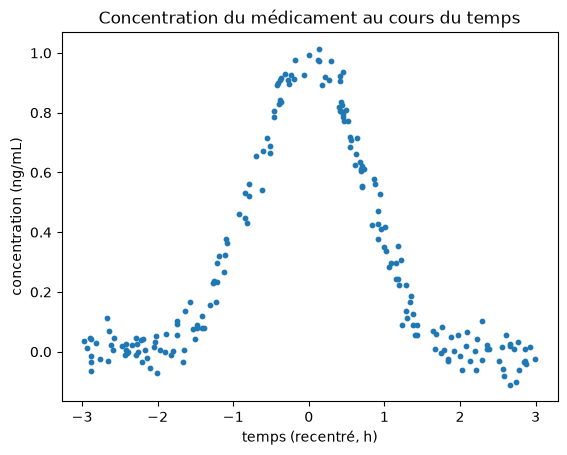

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

np.random.seed(0)
torch.manual_seed(0)

N = 200
x = np.random.uniform(-3, 3, size=N)
t = np.exp(-x**2) + np.random.normal(0, 0.05, size=N)

plt.scatter(x, t, s=10)
plt.xlabel("temps (recentré, h)")
plt.ylabel("concentration (ng/mL)")
plt.title("Concentration du médicament au cours du temps")

## Partie 1 : Prise en main guidée (observer les approximations par morceaux)

On va construire à la main un petit réseau de neurones avec `nn.Sequential`, l'entraîner sur ce jeu de données, puis faire varier sa taille pour observer l'effet sur la fonction apprise.

Un `nn.Sequential` enchaîne des couches : l'entrée traverse la première, puis la deuxième, etc. On utilise deux types de briques :
- `nn.Linear(n_in, n_out)` : une couche de `n_out` neurones, chacun calculant une combinaison affine de ses `n_in` entrées (comme $w_0 + w_1 x$ au TD5, avec ses propres paramètres) ;
- `nn.ReLU()` : l'activation, qui applique $\max(0, \cdot)$ à chaque sortie de la couche précédente.

Notre premier réseau : $x$ (un scalaire) $\to$ une couche cachée de 2 neurones avec activation ReLU $\to$ une couche de sortie à 1 neurone, sans activation (identité), puisqu'on fait de la régression.

In [2]:
# Préparation des tenseurs (forme (N, 1), attendue par nn.Linear)
x_t = torch.tensor(x, dtype=torch.float32).reshape(-1, 1)
t_t = torch.tensor(t, dtype=torch.float32).reshape(-1, 1)

def plot_model(model, title=""):
    plt.scatter(x, t, s=10, label="données")
    xs = torch.linspace(-3, 3, 300).reshape(-1, 1)
    with torch.no_grad():
        ys = model(xs)
    plt.plot(xs.numpy(), ys.numpy(), color="red", label="fonction apprise")
    plt.legend()
    plt.title(title)
    plt.show()

Le code ci-dessous construit ce réseau, puis l'entraîne avec la même démarche qu'au TD5 : calculer la prédiction, la perte, les gradients (`loss.backward()`), puis mettre à jour les poids (`optimizer.step()`). Seul le modèle change : PyTorch s'occupe du calcul des gradients et de la mise à jour. Lisez-le ligne à ligne, puis exécutez-le tel quel.

Perte finale : 0.0938


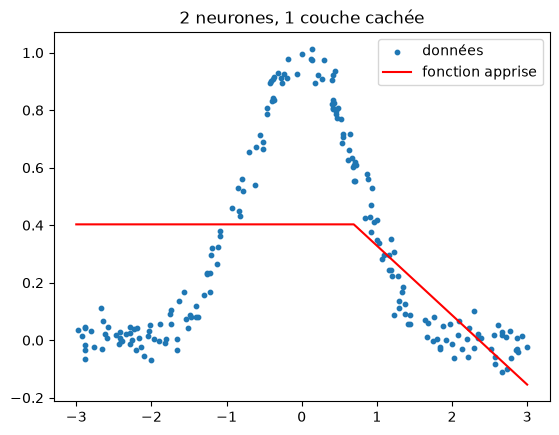

In [3]:
model = nn.Sequential(
    nn.Linear(1, 2),   # couche cachée : 2 neurones
    nn.ReLU(),         # activation des neurones cachés
    nn.Linear(2, 1),   # couche de sortie : 1 neurone, activation identité
)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

for i in range(2000):
    optimizer.zero_grad()                # remet les gradients à zéro
    y = model(x_t)                       # prédictions du réseau
    loss = torch.mean((y - t_t) ** 2)    # perte (erreur quadratique moyenne)
    loss.backward()                      # calcul des gradients (autograd)
    optimizer.step()                     # mise à jour des poids

print(f"Perte finale : {loss.item():.4f}")
plot_model(model, title="2 neurones, 1 couche cachée")

Question 1. Observez la courbe apprise par ce réseau à 2 neurones cachés. À quoi ressemble-t-elle ? Combien de segments distincts observez-vous ?

**Réponse Q1.** Avec 2 neurones ReLU dans la couche cachée, la courbe apprise est une fonction affine par morceaux très grossière : au plus 3 segments de droite (chaque neurone ReLU introduit au plus un point de cassure, donc 2 neurones donnent au plus 2 cassures). Elle ne peut que dessiner une sorte de « toit » ou de rampe, loin de la vraie cloche.

Question 2. Recommencez en construisant le réseau avec davantage de neurones dans la couche cachée (par exemple 4, puis 8, puis 20), toujours avec une seule couche cachée. Reprenez le code ci-dessus : attention, le nombre de neurones cachés apparaît dans deux `nn.Linear` (la sortie de la couche cachée et l'entrée de la couche de sortie). Qu'observez-vous sur la forme de la courbe apprise au fur et à mesure que le nombre de neurones augmente ?

2 neurones : perte finale = 0.0938


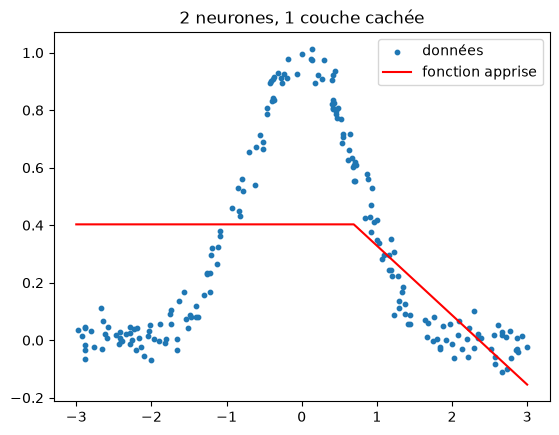

4 neurones : perte finale = 0.0119


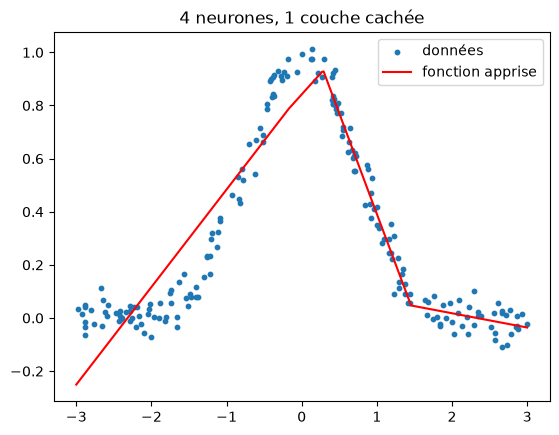

8 neurones : perte finale = 0.0024


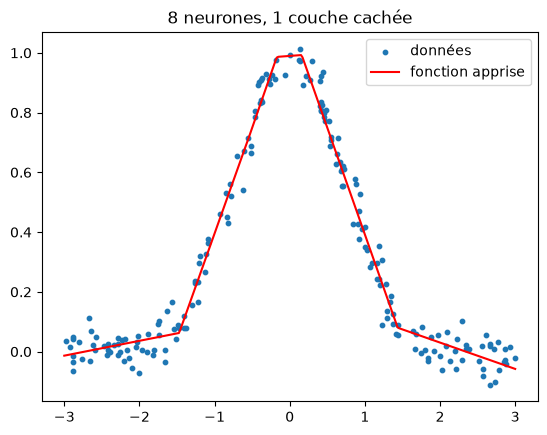

20 neurones : perte finale = 0.0022


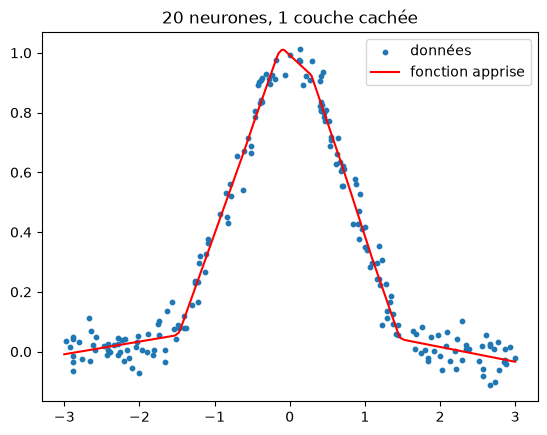

In [4]:
def build_mlp(n_hidden, n_layers=1, n_in=1):
    """MLP : n_layers couches cachées de n_hidden neurones (ReLU), sortie à 1 neurone."""
    layers = [nn.Linear(n_in, n_hidden), nn.ReLU()]
    for _ in range(n_layers - 1):
        layers += [nn.Linear(n_hidden, n_hidden), nn.ReLU()]
    layers.append(nn.Linear(n_hidden, 1))
    return nn.Sequential(*layers)

def fit(model, n_iter=3000, lr=0.05):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for i in range(n_iter):
        optimizer.zero_grad()
        loss = torch.mean((model(x_t) - t_t) ** 2)
        loss.backward()
        optimizer.step()
    return loss.item()

for n_hidden in [2, 4, 8, 20]:
    torch.manual_seed(0)
    model = build_mlp(n_hidden, n_layers=1)
    final_loss = fit(model)
    print(f"{n_hidden} neurones : perte finale = {final_loss:.4f}")
    plot_model(model, title=f"{n_hidden} neurones, 1 couche cachée")

**Réponse Q2.** Plus on ajoute de neurones dans l'unique couche cachée, plus la courbe contient de points de cassure (au plus un par neurone) : elle compte davantage de segments, plus courts, et épouse mieux la cloche. La perte diminue en général jusqu'à se stabiliser autour du niveau du bruit (variance de $\varepsilon$ = $0.05^2 = 0.0025$). Au-delà, ajouter des neurones n'apporte presque plus rien, et un réseau trop grand risquerait de suivre le bruit des données.

Question 3. Reprenez un nombre modéré de neurones (par exemple 4), mais augmentez cette fois le nombre de couches cachées (1, puis 2, puis 3). Pour ajouter une couche cachée, il suffit d'insérer un nouveau couple `nn.Linear(4, 4)`, `nn.ReLU()` dans le `nn.Sequential`. Que se passe-t-il ? Comparez l'effet de l'ajout de couches à l'effet de l'ajout de neurones observé à la question précédente.

1 couche(s) cachée(s) de 4 neurones : perte finale = 0.0119


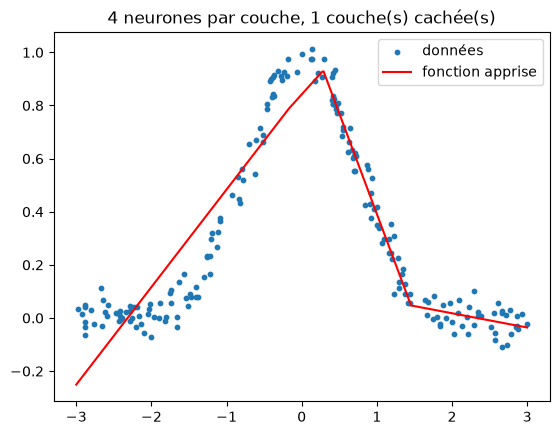

2 couche(s) cachée(s) de 4 neurones : perte finale = 0.0023


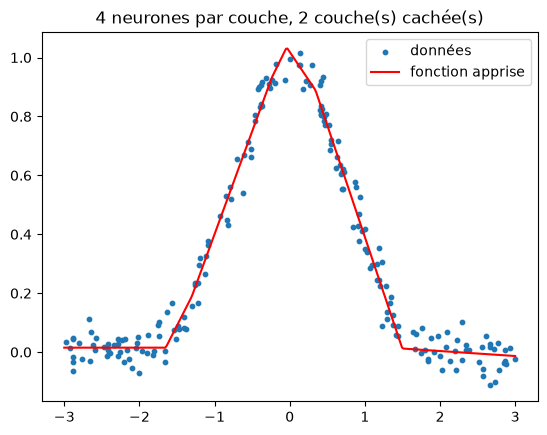

3 couche(s) cachée(s) de 4 neurones : perte finale = 0.0022


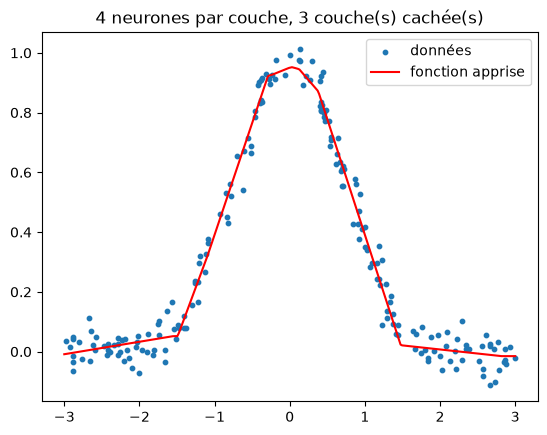

In [5]:
for n_layers in [1, 2, 3]:
    torch.manual_seed(0)
    model = build_mlp(4, n_layers=n_layers)
    final_loss = fit(model, n_iter=3000)
    print(f"{n_layers} couche(s) cachée(s) de 4 neurones : perte finale = {final_loss:.4f}")
    plot_model(model, title=f"4 neurones par couche, {n_layers} couche(s) cachée(s)")

**Réponse Q3.** Ajouter des couches fait aussi augmenter le nombre de segments, mais de façon plus rapide qu'en ajoutant des neurones : chaque couche compose de nouvelles cassures avec celles de la couche précédente, ce qui permet d'obtenir des formes plus riches avec un nombre de paramètres modeste (4 neurones sur 3 couches ≈ 12 neurones, mais la courbe peut être plus variée que 12 neurones sur une seule couche). La contrepartie : l'entraînement est plus délicat (plus sensible à l'initialisation et au pas d'apprentissage), et les résultats peuvent varier d'une graine à l'autre.

Question 4. En une ou deux phrases : pourquoi la fonction apprise par ce réseau est-elle une courbe formée de segments de droites (affine par morceaux), et pas une courbe parfaitement lisse ? Quel est le lien avec l'activation ReLU utilisée dans la couche cachée ?

*Réponse rédigée (pas de code à cette question) :*

Chaque neurone calcule $\max(0, w x + b)$ : c'est une fonction affine de part et d'autre du point où $wx + b = 0$, avec un coude (non dérivable) en ce point. Le réseau n'est qu'une combinaison de telles fonctions, donc c'est une fonction affine par morceaux : les points de cassure sont ceux où l'entrée d'un neurone ReLU change de signe. Comme ReLU n'est pas une fonction lisse, la courbe obtenue est faite de segments de droites et non d'une courbe parfaitement arrondie ; elle ne devient visuellement lisse que lorsque les segments sont très nombreux et très courts.

## Partie 2 : À vous de construire la meilleure architecture

Vous avez observé que plus de neurones ou plus de couches permettent de mieux approximer la cloche, au prix d'un réseau plus complexe. À vous maintenant de choisir une architecture (nombre de couches, nombre de neurones par couche) qui approxime bien la fonction, sans forcément aller à l'extrême.

Question 5. Vous avez probablement recopié plusieurs fois le même bloc (construction du réseau, boucle d'entraînement). Regroupez-le dans une fonction `train_model` dont vous choisissez les paramètres (par exemple le nombre de neurones, le nombre de couches cachées, le nombre d'itérations et le pas d'apprentissage). Entraînez ensuite votre modèle, affichez la courbe apprise, et indiquez la perte finale obtenue. Essayez plusieurs configurations avant de vous arrêter sur un choix, et justifiez brièvement votre choix final (nombre de couches, de neurones, nombre d'itérations, pas d'apprentissage).

[1 couche(s) x 4 neurones, 3000 it., lr=0.01] perte finale = 0.01185
[1 couche(s) x 8 neurones, 3000 it., lr=0.01] perte finale = 0.01224
[2 couche(s) x 8 neurones, 3000 it., lr=0.01] perte finale = 0.00209
[2 couche(s) x 8 neurones, 6000 it., lr=0.01] perte finale = 0.00207
[2 couche(s) x 16 neurones, 6000 it., lr=0.01] perte finale = 0.00212
[2 couche(s) x 8 neurones, 3000 it., lr=0.1] perte finale = 0.00217
[2 couche(s) x 8 neurones, 6000 it., lr=0.01] perte finale = 0.00207


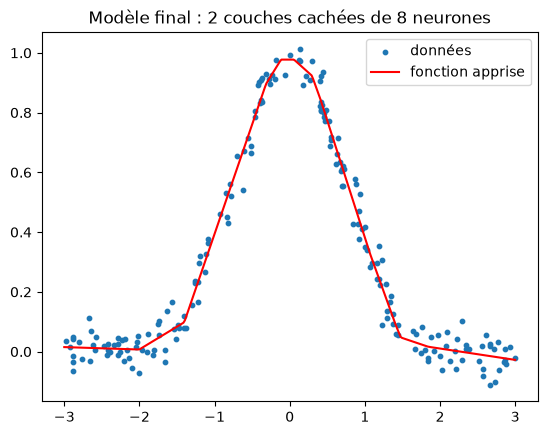

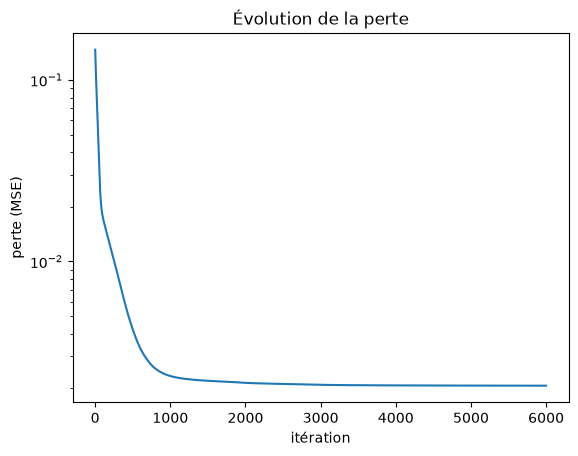

Perte finale du modèle choisi : 0.00207  (plancher dû au bruit : 0.00250)


In [6]:
def train_model(n_hidden=8, n_layers=2, n_iter=5000, lr=0.01, momentum=0.9, seed=0, verbose=True):
    """Construit un MLP (n_layers couches cachées de n_hidden neurones ReLU),
    l'entraîne par SGD avec momentum sur (x_t, t_t) et renvoie (modèle, historique de perte)."""
    torch.manual_seed(seed)
    model = build_mlp(n_hidden, n_layers)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    history = []
    for i in range(n_iter):
        optimizer.zero_grad()
        loss = torch.mean((model(x_t) - t_t) ** 2)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    if verbose:
        print(f"[{n_layers} couche(s) x {n_hidden} neurones, {n_iter} it., lr={lr}] perte finale = {history[-1]:.5f}")
    return model, history

# Comparaison de plusieurs configurations
configs = [
    dict(n_hidden=4,  n_layers=1, n_iter=3000, lr=0.01),
    dict(n_hidden=8,  n_layers=1, n_iter=3000, lr=0.01),
    dict(n_hidden=8,  n_layers=2, n_iter=3000, lr=0.01),
    dict(n_hidden=8,  n_layers=2, n_iter=6000, lr=0.01),
    dict(n_hidden=16, n_layers=2, n_iter=6000, lr=0.01),
    dict(n_hidden=8,  n_layers=2, n_iter=3000, lr=0.1),
]
for cfg in configs:
    train_model(**cfg)

# Choix final
best_model, best_history = train_model(n_hidden=8, n_layers=2, n_iter=6000, lr=0.01)
plot_model(best_model, title="Modèle final : 2 couches cachées de 8 neurones")
plt.plot(best_history)
plt.yscale("log")
plt.xlabel("itération")
plt.ylabel("perte (MSE)")
plt.title("Évolution de la perte")
plt.show()
print(f"Perte finale du modèle choisi : {best_history[-1]:.5f}  (plancher dû au bruit : {0.05**2:.5f})")

*Justification de votre choix d'architecture (texte) :*

J'ai retenu **2 couches cachées de 8 neurones** (≈ 100 paramètres), entraînées pendant **6000 itérations** avec un **pas d'apprentissage de 0.01** (SGD avec momentum 0.9).

- **Architecture** : une seule couche de 4 neurones est trop grossière (peu de segments) ; 2 couches de 8 neurones suffisent à reproduire la cloche avec peu de segments bien placés. Passer à 16 neurones par couche ne fait baisser la perte que marginalement : on vise un niveau proche du plancher dû au bruit (variance $0.05^2 = 0.0025$), car descendre beaucoup plus bas reviendrait à apprendre le bruit (surapprentissage).
- **Nombre d'itérations** : 3000 itérations laissent encore la perte décroître ; 6000 permettent à la courbe de converger (la courbe de perte devient quasi plate).
- **Pas d'apprentissage** : 0.01 avec momentum donne une décroissance régulière ; avec 0.1 l'entraînement est plus rapide mais plus instable (perte plus bruitée, voire divergence selon l'initialisation).

(Les valeurs exactes de perte sont à lire dans les sorties ci-dessus : elles dépendent de la graine.)

## Partie 3 : Un nouveau jeu de données

On vous donne maintenant un nouveau jeu de données, avec deux variables $x_1$ et $x_2$, et une étiquette binaire $y \in \{0, 1\}$ pour chaque point. Exécutez la cellule ci-dessous pour le générer et le visualiser (sans chercher à deviner d'où il vient : contentez-vous d'abord de l'observer).

Text(0.5, 1.0, 'Nouveau jeu de données')

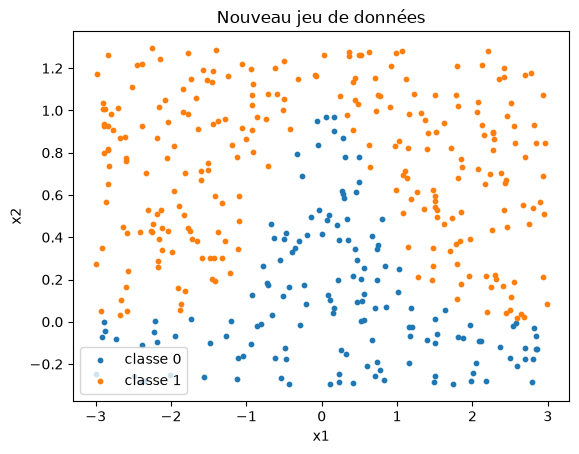

In [7]:
np.random.seed(1)

N2 = 400
x1 = np.random.uniform(-3, 3, size=N2)
x2 = np.random.uniform(-0.3, 1.3, size=N2)
label = (x2 > np.exp(-x1**2)).astype(np.float32)

plt.scatter(x1[label == 0], x2[label == 0], s=10, label="classe 0")
plt.scatter(x1[label == 1], x2[label == 1], s=10, label="classe 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("Nouveau jeu de données")

Question 6. D'après le graphique, les deux classes vous semblent-elles séparables ? Quelle est la nature de ce problème (régression ou classification) ? Quelle fonction d'erreur et quelle activation de sortie semblent adaptées ?

*Réponse rédigée :*

Les deux classes ne sont **pas séparables par une droite** (la classe 1 est au-dessus d'une courbe en cloche, la classe 0 en dessous), mais elles sont bien **séparables par une frontière courbe** : à part près de la frontière, les nuages ne se mélangent pas. Il s'agit d'un problème de **classification binaire** (l'étiquette $y \in \{0, 1\}$ est discrète), et non de régression.

- **Fonction d'erreur** : l'entropie croisée binaire (BCE), plutôt que l'erreur quadratique.
- **Activation de sortie** : la sigmoïde, qui donne une probabilité $P(y=1 \mid x_1, x_2) \in [0,1]$. En PyTorch, on utilise `BCEWithLogitsLoss` (ou `F.binary_cross_entropy_with_logits`) qui intègre la sigmoïde de façon numériquement stable ; la dernière couche reste donc `nn.Linear(., 1)` et on applique `torch.sigmoid` seulement pour prédire. On prédit la classe 1 si la probabilité dépasse 0.5.

Question 7. Construisez et entraînez un réseau de neurones adapté à ce problème (entrée à 2 dimensions, architecture et fonction d'erreur de votre choix). Affichez l'évolution de la perte au cours de l'entraînement, et visualisez la frontière de décision apprise par votre modèle, superposée au nuage de points (vous pouvez par exemple évaluer le modèle sur une grille fine de points du plan, et afficher la zone où le modèle prédit la classe 1).

Indication : pour une bonne frontière de décision, il n'est pas forcément nécessaire d'utiliser une architecture très différente de celles de la partie 1.

In [8]:
x_t = torch.tensor(np.column_stack([x1, x2]), dtype=torch.float32)
t_t = torch.tensor(label, dtype=torch.float32).reshape(-1, 1)

In [9]:
import torch.nn.functional as F

Perte finale : 0.0001 | précision sur les données : 1.000


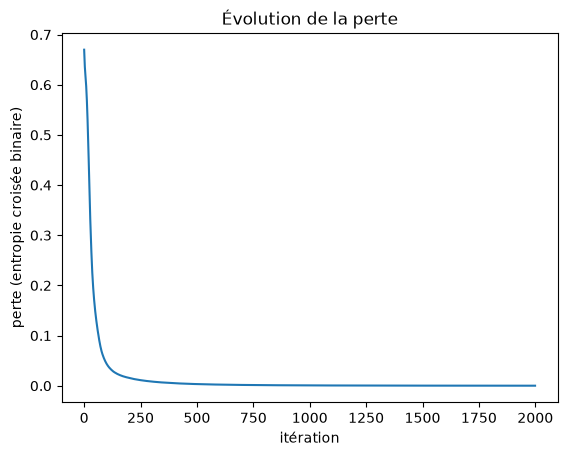

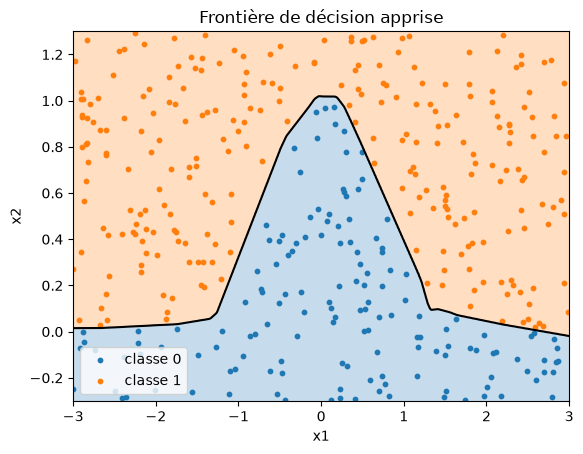

In [10]:
torch.manual_seed(0)

clf = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1),            # logit : la sigmoïde est intégrée à la perte
)
optimizer = torch.optim.Adam(clf.parameters(), lr=0.01)

losses = []
for i in range(2000):
    optimizer.zero_grad()
    logits = clf(x_t)
    loss = F.binary_cross_entropy_with_logits(logits, t_t)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

with torch.no_grad():
    acc = ((clf(x_t) > 0).float() == t_t).float().mean().item()
print(f"Perte finale : {losses[-1]:.4f} | précision sur les données : {acc:.3f}")

# Évolution de la perte
plt.figure()
plt.plot(losses)
plt.xlabel("itération")
plt.ylabel("perte (entropie croisée binaire)")
plt.title("Évolution de la perte")
plt.show()

# Frontière de décision
g1, g2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-0.3, 1.3, 300))
grid = torch.tensor(np.column_stack([g1.ravel(), g2.ravel()]), dtype=torch.float32)
with torch.no_grad():
    proba = torch.sigmoid(clf(grid)).reshape(g1.shape).numpy()

plt.figure()
plt.contourf(g1, g2, proba > 0.5, levels=[-0.5, 0.5, 1.5], alpha=0.25, colors=["tab:blue", "tab:orange"])
plt.contour(g1, g2, proba, levels=[0.5], colors="k")
plt.scatter(x1[label == 0], x2[label == 0], s=10, label="classe 0")
plt.scatter(x1[label == 1], x2[label == 1], s=10, label="classe 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("Frontière de décision apprise")
plt.show()

Question 8. Comparez la frontière de décision que vous venez d'obtenir avec la fonction de régression que vous aviez apprise en partie 1 ou 2 (vous pouvez les superposer sur un même graphique). Que remarquez-vous ? Qu'est-ce que cela vous apprend sur la façon dont ce second jeu de données a été construit ?

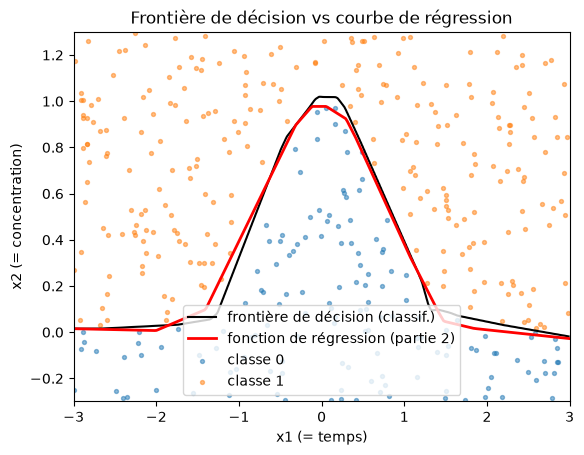

In [11]:
xs = torch.linspace(-3, 3, 300).reshape(-1, 1)
with torch.no_grad():
    y_reg = best_model(xs).squeeze().numpy()       # fonction de régression (partie 2)

plt.figure()
plt.contour(g1, g2, proba, levels=[0.5], colors="k")
plt.plot([], [], color="k", label="frontière de décision (classif.)")
plt.plot(xs.squeeze().numpy(), y_reg, color="red", linewidth=2, label="fonction de régression (partie 2)")
plt.scatter(x1[label == 0], x2[label == 0], s=8, alpha=0.5, label="classe 0")
plt.scatter(x1[label == 1], x2[label == 1], s=8, alpha=0.5, label="classe 1")
plt.xlabel("x1 (= temps)")
plt.ylabel("x2 (= concentration)")
plt.legend()
plt.title("Frontière de décision vs courbe de régression")
plt.show()

*Réponse rédigée :*

La frontière de décision apprise en classification se superpose presque exactement à la courbe en cloche apprise en régression : c'est la même courbe, vue sous deux angles. Cela montre que le second jeu de données a été construit à partir de la **même fonction** $x_2 = \exp(-x_1^2)$ : on tire des points $(x_1, x_2)$ dans le plan, et l'étiquette vaut 1 si le point est **au-dessus** de la courbe, 0 sinon (c'est exactement le code qui génère `label`). Autrement dit, la courbe de la partie 1 devient ici une frontière séparant deux classes. Les deux problèmes ont la même difficulté d'approximation (une cloche), mais pas la même formulation : en régression on prédit la hauteur de la courbe en $x$ (erreur quadratique, sortie linéaire) ; en classification on prédit de quel côté de la courbe se trouve un point (entropie croisée, sortie sigmoïde). Les petites différences entre les deux courbes viennent du bruit et de l'échantillonnage (en régression) et des points proches de la frontière (en classification).

## Bilan

Vous avez construit et entraîné, avec PyTorch, de véritables réseaux de neurones à une ou plusieurs couches cachées, en laissant PyTorch calculer les gradients (autograd) et mettre à jour les poids (optimiseur SGD) automatiquement. Vous avez observé que l'activation ReLU produit des approximations affines par morceaux, dont la finesse augmente avec le nombre de neurones, et dont la structure se complexifie avec le nombre de couches. Enfin, vous avez découvert par vous-même qu'un même phénomène (ici une courbe en cloche) peut se voir soit comme une fonction à approximer (régression), soit comme une frontière séparant deux classes (classification), et que le choix de la fonction d'erreur et de l'activation de sortie dépend de cette interprétation, pas de l'architecture des couches cachées elle-même.

Le prochain TP (noté) vous donnera un nouveau jeu de données sans autre indication : ce sera à vous de choisir la nature du problème, la fonction d'erreur, l'architecture, et de chercher la meilleure performance possible.